# 3 · Tuning: Hyperparameter Selection with Optuna

This notebook selects the structural and regularization hyperparameters of the
marketing mix model. It does **not** estimate channel effects; those are learned
by the model itself in `4_modeling`.

## What is tuned

| Hyperparameter | Search space | Purpose |
|---|---|---|
| `k_yearly` | 1–6 | Number of Fourier harmonics for annual seasonality. Only two years of data are available, so this is weakly identified and worth tuning. |
| `l_max` | 7 / 14 / 21 days | Length of the adstock (carry-over) window. |
| `saturation` | logistic / Hill | Logistic saturation can only show diminishing returns. Hill is S-shaped and also allows returns to increase at low spend, as the task describes. |
| `beta_sigma` | 0.1–0.6 (log scale) | Prior scale on each channel's maximum effect; controls regularization strength. The upper bound is capped because larger values fail the prior predictive check in `4_modeling` (prior mean forecast in the thousands of customers/day against an observed ≈ 430), while the MAP cross-validation cannot see this. |
| `bf_features` | `peak` / `peak+window` / `peak+window+bf+cm` | Black Friday / Cyber Monday indicators. The largest residuals of the baseline model fall in the BF window. |

## Method

- **Objective:** mean MAPE across three expanding-window (rolling-origin) folds
  inside the training period. Cutoffs are 2025-10-01, 2026-01-01 and 2026-04-01;
  each fold trains on all data before the cutoff and forecasts the following
  90 days. Fold 1 includes Black Friday, Cyber Monday and Christmas, so
  candidates are judged on event periods as well as ordinary ones.
- **Prediction:** the model's expected value (`mu`, without observation noise),
  so the metric is not distorted by random noise. Adstock history is carried
  over from the end of each training window.
- **Search:** seeded TPE sampler with a median pruner. The default configuration
  is evaluated first and serves as the baseline for comparison.
- **Estimation:** MAP (point estimate) instead of full MCMC. Running MCMC for
  every trial would take hours; MAP is fast and adequate for comparing model
  structures. The final model in `4_modeling` is fitted with full MCMC.
- **Hold-out:** the final hold-out period (from `holdout_start`) is never used
  during the search. It is used only afterwards to check whether tuning
  overfitted the cross-validation folds.

## Acceptance rule

A tuned configuration replaces the default **only if it beats the default both
on cross-validation and on the independent hold-out**. Otherwise the default is
kept, and the notebook states this explicitly.

## Outputs

- `data/processed/best_params.json`: chosen configuration, default and
  best-by-CV configurations, their CV and hold-out scores, and the top five
  configurations. `4_modeling` reads the `chosen` entry.
- `data/processed/optuna_trials.csv`: all trials with parameters, fold scores
  and status.

## Limitations

1. Three folds and about twenty trials make it easy to fit noise. The
   acceptance rule above is the safeguard against this.
2. The best forecast is not necessarily the best causal estimate of channel
   effects. Hyperparameters are therefore chosen for predictive accuracy only,
   and the top-five configurations are reused in `05_scenarios` to check
   whether the **conclusions about channels** stay stable.
3. MAP scores rank configurations but do not carry posterior uncertainty.

In [1]:
import os, sys
from pathlib import Path
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# --- Colab ---
#PROJECT_DIR = "/content/drive/MyDrive/digis"
#  local ---
PROJECT_DIR = "."

if IN_COLAB:
    drive.mount("/content/drive")
root = Path(PROJECT_DIR).resolve()
if not (root / "notebooks").exists() and (root.parent / "notebooks").exists():
    root = root.parent
assert (root / "notebooks" / "common.py").exists(), (
    f"Not found {root}/notebooks/common.py.")
os.chdir(root / "notebooks"); sys.path.insert(0, str(root / "notebooks"))
print("root :", root, "| Colab:", IN_COLAB)

Mounted at /content/drive
root : /content/drive/MyDrive/digis | Colab: True


In [2]:
import importlib.util
for pkg, spec in (("pymc_marketing", "pymc-marketing==1.3.0"), ("optuna", "optuna"), ("sklearn", "scikit-learn")):
    if importlib.util.find_spec(pkg) is None:
        get_ipython().run_line_magic("pip", f"install -q {spec}")
        print("Installed", spec)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.
Installed pymc-marketing==1.3.0
Installed optuna


In [3]:
import os, json, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, optuna
import importlib, common
importlib.reload(common)
from common import OUT_DIR, make_mmm, OPTIONAL_CONTROLS


In [4]:
warnings.filterwarnings("ignore"); optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width",160); pd.set_option("display.max_columns",30)

cfg = json.load(open(OUT_DIR/"config.json")); df = pd.read_csv(OUT_DIR/"model_input.csv", parse_dates=["date"])
CH, CT = cfg["channels"], cfg["controls"]; SPLIT = pd.Timestamp(cfg["holdout_start"])

# ---- parameters ----
SEED = 42
N_TRIALS = 20                 # total trials (including default)
TIME_BUDGET_MIN = 45          # strict time limit, min
FOLD_CUTS = ["2025-10-01", "2026-01-01", "2026-04-01"]   # train < cut, test = next FOLD_DAYS
FOLD_DAYS = 90
DEFAULT = dict(k_yearly=3, l_max=14, saturation="logistic", beta_sigma=0.5, bf_features="peak")

train = df[df.date<SPLIT].reset_index(drop=True); hold = df[df.date>=SPLIT].reset_index(drop=True)
assert all(pd.Timestamp(c)+pd.Timedelta(days=FOLD_DAYS) <= SPLIT for c in FOLD_CUTS), "fold enters hold-out"
print("train",len(train),"| hold-out",len(hold),"| folds:",FOLD_CUTS)

train 640 | hold-out 90 | folds: ['2025-10-01', '2026-01-01', '2026-04-01']


## Evaluation Function
For each configuration: MAP training → forecast of the **expected value `mu` without observation noise** (so the metric is not distorted by random noise) → MAPE.
Setting `include_last_observations=True` carries over the adstock tail of media spend from the end of the training period.

In [5]:
def controls_for(p): return CT + OPTIONAL_CONTROLS[p["bf_features"]]

def fit_map(p, tr):
    m = make_mmm(CH, controls_for(p), p["k_yearly"], p["l_max"], p["saturation"], p["beta_sigma"])
    cols = ["date"]+CH+controls_for(p)
    m.fit(tr[cols], tr["new"], method="map", random_seed=SEED, progressbar=False)
    return m, cols

def predict_mu(m, cols, te):
    S = float(m.get_scales_as_xarray()["target_scale"])
    mu = m.sample_posterior_predictive(te[cols], extend_idata=False, combined=False,
                                       include_last_observations=True, var_names=["mu"], random_seed=SEED)["mu"]
    return mu.mean(("chain","draw")).values*S

def mape(p, y): return float(np.mean(np.abs(p-y)/y))

def fold_scores(p):
    out=[]
    for cut in FOLD_CUTS:
        tr = df[df.date<cut]; te = df[(df.date>=cut)&(df.date<pd.Timestamp(cut)+pd.Timedelta(days=FOLD_DAYS))]
        m, cols = fit_map(p, tr); out.append(mape(predict_mu(m, cols, te), te.new.values))
    return out

## Optuna: Search Space, Pruner, and Execution

In [6]:
def suggest(trial):
    return dict(k_yearly=trial.suggest_int("k_yearly",1,6),
                l_max=trial.suggest_categorical("l_max",[7,14,21]),
                saturation=trial.suggest_categorical("saturation",["logistic","hill"]),
                beta_sigma=trial.suggest_float("beta_sigma",0.1,0.6,log=True),
                bf_features=trial.suggest_categorical("bf_features",list(OPTIONAL_CONTROLS)))

def objective(trial):
    p = suggest(trial); scores=[]
    for i,cut in enumerate(FOLD_CUTS):
        tr = df[df.date<cut]; te = df[(df.date>=cut)&(df.date<pd.Timestamp(cut)+pd.Timedelta(days=FOLD_DAYS))]
        try:
            m, cols = fit_map(p, tr); s = mape(predict_mu(m, cols, te), te.new.values)
        except Exception as e:    # unstable MAP convergence → prune trial
            trial.set_user_attr("error", str(e)[:200]); raise optuna.TrialPruned()
        if not np.isfinite(s): raise optuna.TrialPruned()
        scores.append(s); trial.report(float(np.mean(scores)), i)
        if trial.should_prune(): trial.set_user_attr("fold_mape", scores); raise optuna.TrialPruned()
    trial.set_user_attr("fold_mape", scores)
    return float(np.mean(scores))

study = optuna.create_study(direction="minimize", study_name="mmm_tuning",
                            sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=6),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=6, n_warmup_steps=0))
study.enqueue_trial(DEFAULT)      # "default" evaluated first: baseline for comparison
t0=time.time(); study.optimize(objective, n_trials=N_TRIALS, timeout=TIME_BUDGET_MIN*60)
print(f"Trials in database: {len(study.trials)} | Current run time: {(time.time()-t0)/60:.1f} min")

Output()

Output()

Output()

Output()

Output()

Output()

... (43 outputs left out)

Output()

Output()

Output()

Trials in database: 20 | Current run time: 34.5 min


## Results

Completed: 15 | Pruned/Error: 5
 number  value  k_yearly  l_max saturation  beta_sigma bf_features
      7 0.0817         6     21   logistic      0.5490 peak+window
     13 0.0819         6      7   logistic      0.4540 peak+window
     12 0.0820         6      7   logistic      0.3979 peak+window
     11 0.0824         6     21   logistic      0.3156 peak+window
      6 0.0836         5     21   logistic      0.2349 peak+window
     16 0.0842         5     14   logistic      0.5461 peak+window
     14 0.0876         5      7   logistic      0.3534        peak
     19 0.0879         4     21   logistic      0.5027 peak+window

Default configuration (trial 0): MAPE CV = 0.1142
Importance: {'k_yearly': 0.66, 'beta_sigma': 0.32, 'bf_features': 0.01, 'l_max': 0.01, 'saturation': 0.0}


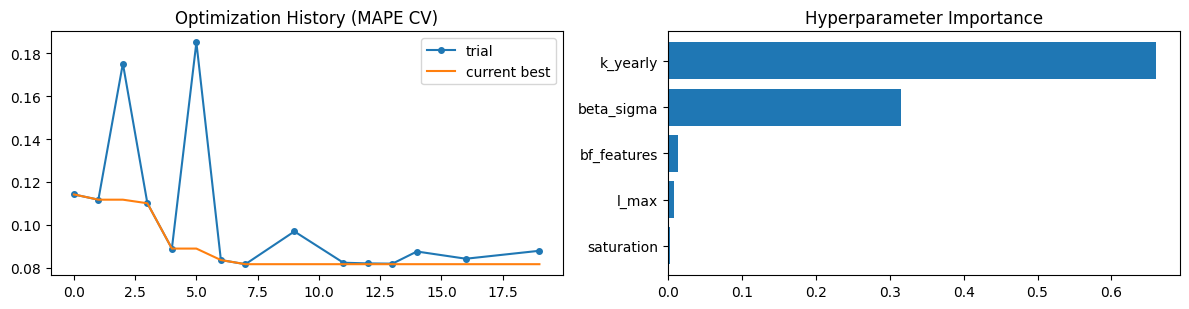

In [7]:
tr_ = study.trials_dataframe(attrs=("number","value","state","params","user_attrs"))
tr_.columns=[c.replace("params_","") for c in tr_.columns]
comp = tr_[tr_.state=="COMPLETE"].sort_values("value")
print("Completed:", len(comp), "| Pruned/Error:", int((tr_.state!="COMPLETE").sum()))
show=["number","value","k_yearly","l_max","saturation","beta_sigma","bf_features"]
print(comp[show].head(8).round(4).to_string(index=False))
default_row = tr_[(tr_.number==0)]
print("\nDefault configuration (trial 0): MAPE CV =", round(float(default_row.value.iloc[0]),4) if default_row.state.iloc[0]=="COMPLETE" else default_row.state.iloc[0])
fig,ax=plt.subplots(1,2,figsize=(12,3.2))
ax[0].plot(comp.sort_values("number").number, comp.sort_values("number").value,"o-",ms=4,label="trial"); ax[0].plot(comp.sort_values("number").number, comp.sort_values("number").value.cummin(),label="current best"); ax[0].set_title("Optimization History (MAPE CV)"); ax[0].legend()
try:
    imp=optuna.importance.get_param_importances(study); ax[1].barh(list(imp)[::-1],list(imp.values())[::-1]); ax[1].set_title("Hyperparameter Importance"); print("Importance:",{k:round(v,2) for k,v in imp.items()})
except Exception as e: ax[1].set_title("Importance unavailable"); print("importance:",str(e)[:80])
plt.tight_layout(); plt.show()

### Where does the improvement come from?
Two checks before trusting the winner. (1) **Per-fold errors:** fold 1 contains Black Friday, Cyber Monday and Christmas. With only one earlier year of data, a high-order yearly Fourier term can simply memorise last year's season; if almost all of the gain comes from fold 1, the winner is good at repeating one known event period, not necessarily better in general. (2) **Near-ties:** if many configurations are within 2% of the best CV error, the CV does not distinguish between them, and among those we should prefer the one with the most plausible priors.

In [8]:
t_def, t_best = study.trials[0], study.best_trial
fd, fb = t_def.user_attrs.get("fold_mape"), t_best.user_attrs.get("fold_mape")
if fd and fb:
    pf = pd.DataFrame({"fold (train up to → test next %d days)" % FOLD_DAYS: FOLD_CUTS, "default": fd, "best": fb})
    pf["relative improvement"] = 1 - pf["best"] / pf["default"]
    display(pf.round(4))
    share1 = (fd[0] - fb[0]) / max(sum(d - b for d, b in zip(fd, fb)), 1e-12)
    print(f"Share of the total MAPE gain that comes from fold 1 (BF + Christmas): {share1:.0%}")
near = comp[comp.value <= comp.value.min() * 1.02]
print(f"\nConfigurations within 2% of the best CV error: {len(near)} of {len(comp)} completed")
display(near[show].round(4))

,fold (train up to → test next 90 days),default,best,relative improvement
0,2025-10-01,0.1458,0.0953,0.3462
1,2026-01-01,0.1225,0.0815,0.3341
2,2026-04-01,0.0743,0.0682,0.0829


Share of the total MAPE gain that comes from fold 1 (BF + Christmas): 52%

Configurations within 2% of the best CV error: 4 of 15 completed


,number,value,k_yearly,l_max,saturation,beta_sigma,bf_features
7,7,0.0817,6,21,logistic,0.5490,peak+window
13,13,0.0819,6,7,logistic,0.4540,peak+window
12,12,0.0820,6,7,logistic,0.3979,peak+window
11,11,0.0824,6,21,logistic,0.3156,peak+window


### Is the winning `k_yearly` an artefact of the search bound?
The best `k_yearly` sits at the upper end of the search range, so we check whether the error keeps falling beyond it. We re-fit the winning configuration with other values of `k_yearly` on two folds: the **event fold** (Black Friday + Christmas) and a **calm fold** (no events). If the error rises again at a larger `k` on the event fold, the optimum is interior and the range does not need to be extended. Comparing the two folds also shows where the gain comes from: a large gain only on the event fold means the Fourier terms are mostly learning last year's seasonal event pattern rather than improving the model in general.
Set `RUN_K_SCAN = False` to skip (about 3 minutes).

In [9]:
RUN_K_SCAN = True
SCAN_CUTS = {"event fold (BF + Christmas)": "2025-10-01", "calm fold (no events)": "2026-04-01"}
BEST = dict(study.best_trial.params)            # найкраща конфігурація за CV
K_SCAN = sorted(set([3, int(BEST["k_yearly"]), 10]))
if RUN_K_SCAN:
    scan = {}
    for k in K_SCAN:
        for name, cut in SCAN_CUTS.items():
            tr = df[df.date < cut]; te = df[(df.date >= cut) & (df.date < pd.Timestamp(cut) + pd.Timedelta(days=FOLD_DAYS))]
            m, cols = fit_map({**BEST, "k_yearly": k}, tr)
            scan[(name, k)] = mape(predict_mu(m, cols, te), te.new.values)
    k_scan = pd.Series(scan).unstack(1)
    k_scan.index.name = "fold"; k_scan.columns = [f"k={c}" for c in k_scan.columns]
    display(k_scan.round(4))
    kb = f"k={int(BEST['k_yearly'])}"
    for fold in k_scan.index:
        row = k_scan.loc[fold]
        print(f"{fold}: best k in scan = {row.idxmin()} | error at {kb}: {row[kb]:.4f} | largest k: {row.iloc[-1]:.4f}")
    ev = k_scan.loc["event fold (BF + Christmas)"]
    print("\nInterior optimum on the event fold (error rises again at the largest k):", bool(ev.iloc[-1] > ev.min() * 1.02))

Output()

Output()

Output()

Output()

Output()

Output()

,k=3,k=6,k=10
fold,,,
calm fold (no events),0.071,0.0682,0.0685
event fold (BF + Christmas),0.115,0.0953,0.1110


calm fold (no events): best k in scan = k=6 | error at k=6: 0.0682 | largest k: 0.0685
event fold (BF + Christmas): best k in scan = k=6 | error at k=6: 0.0953 | largest k: 0.1110

Interior optimum on the event fold (error rises again at the largest k): True


## Overfitting Safeguard: Independent Hold-out
Tuning is accepted **only if the best configuration beats the default on both CV and the independent hold-out** (which the tuner hasn't seen). Otherwise, we revert to the default — proving that "tuning doesn't significantly help" is also a valid outcome.

In [10]:
best_p = dict(study.best_trial.params)
def holdout_mape(p):
    m, cols = fit_map(p, train); return mape(predict_mu(m, cols, hold), hold.new.values)
h_def, h_best = holdout_mape(DEFAULT), holdout_mape(best_p)
cv_def = float(default_row.value.iloc[0]) if default_row.state.iloc[0]=="COMPLETE" else np.nan
cv_best = float(study.best_value)
print(pd.DataFrame({"CV MAPE":[cv_def,cv_best],"hold-out MAPE (MAP)":[h_def,h_best]},index=["default","best"]).round(4))
accept = (cv_best < cv_def) and (h_best <= h_def)
CHOSEN = best_p if accept else DEFAULT
print("\nVERDICT:", "Tuning ACCEPTED (outperforms on both CV and hold-out)" if accept else "Tuning NOT confirmed on hold-out → reverting to default configuration")
print("Chosen configuration:", CHOSEN)

Output()

Output()

         CV MAPE  hold-out MAPE (MAP)
default   0.1142               0.0923
best      0.0817               0.0725

VERDICT: Tuning ACCEPTED (outperforms on both CV and hold-out)
Chosen configuration: {'k_yearly': 6, 'l_max': 21, 'saturation': 'logistic', 'beta_sigma': 0.5489779514362569, 'bf_features': 'peak+window'}


## Saving Results

In [11]:
top5 = [dict(t.params, cv_mape=t.value) for t in sorted([t for t in study.trials if t.state.name=="COMPLETE"], key=lambda t:t.value)[:5]]
out = dict(chosen=CHOSEN, tuning_accepted=bool(accept), default=DEFAULT, best_by_cv=best_p,
           cv=dict(default=cv_def,best=cv_best), holdout_map=dict(default=h_def,best=h_best),
           top5_by_cv=top5, n_trials=len(study.trials), folds=FOLD_CUTS, fold_days=FOLD_DAYS, seed=SEED)
json.dump(out, open(OUT_DIR/"best_params.json","w"), indent=2, ensure_ascii=False, default=float)
tr_.to_csv(OUT_DIR/"optuna_trials.csv", index=False)
print("Saved best_params.json and optuna_trials.csv to", OUT_DIR)

Saved best_params.json and optuna_trials.csv to /content/drive/MyDrive/digis/data/processed
